In [ ]:
#Mount your drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Code

Download and load the MNIST dataset using the provided function load_data(), and:
1. Calculate pixelwise mean, variance, eigenvectors and eigenvalues.
2. Plot the mean and the first 10 eigenvector images.
3. Plot the first 100 eigenvalues.

In [ ]:
import six.moves.cPickle as pickle
import gzip
import os
import numpy as np
from PIL import Image
from numpy import linalg as LA
import matplotlib.pyplot as plt
import urllib.request

In [ ]:
def load_data(dataset):
    ''' Loads the dataset

    :type dataset: string
    :param dataset: the path to the dataset (here MNIST)

    copied from http://deeplearning.net/ and revised by hchoi
    '''

    # Download the MNIST dataset if it is not present
    if not os.path.isfile(dataset):
        origin = (
            'http://www.iro.umontreal.ca/~lisa/deep/data/mnist/mnist.pkl.gz'
        )
        print('Downloading data from %s' % origin)
        urllib.request.urlretrieve(origin, dataset)

    print('Loading data...')

    # Load the dataset
    with gzip.open(dataset, 'rb') as f:
        try:
            train_set, valid_set, test_set = pickle.load(f, encoding='latin1')
        except:
            train_set, valid_set, test_set = pickle.load(f)
    # train_set, valid_set, test_set format: tuple(input, target)
    # input is a numpy.ndarray of 2 dimensions (a matrix)
    # where each row corresponds to an example. target is a
    # numpy.ndarray of 1 dimension (vector) that has the same length as
    # the number of rows in the input. It should give the target
    # to the example with the same index in the input.
    print('... data has been loaded!')
    return train_set, valid_set, test_set

In [ ]:
#Load the data into train, validation and test sets
train_set, val_set, test_set = load_data('mnist.pkl.gz')

#Separate each set into image vector (_x) and label (_y)
train_x, train_y = train_set
val_x, val_y = val_set
test_x, test_y = test_set

Loading data...
... data has been loaded!


In [ ]:
#Check that the shapes (dimensions) of the labels make sense.
print(train_x.shape)
print(train_y.shape)
#Answer these questions to yourself: what do these dimensions mean? How many data samples are there?

(50000, 784)
(50000,)


## Mean, variance, eigenvectors and eigenvalues.

In [ ]:
#Compute the pixelwise mean of the images from train_x. Complete the ... space with your code
mean_img = train_x.mean(axis=0)
#Check the shape. It should be (784,)
print(mean_img.shape)

(784,)


In [ ]:
#Compute the pixelwise variance of the images from train_x. Complete the ... space with your code
var_img = train_x.var(axis=0)
#Check the shape. It should be (784,)
print(var_img.shape)

(784,)


In [ ]:
#Compute the eigenvectors and eigenvalues, complete ... with your code
#first, compute the covariance matrix of train_x (careful with the dimensions)
#rowvar=False: the relationship is transposed: each column represents a variable, while the rows contain observations.
cov = np.cov(train_x, rowvar=False)
#Check the shape, it should be (784, 784)
print(cov.shape)
#Get the eigenvalues and eigenvectors
eigval, eigvec = np.linalg.eig(cov)
#Print their shapes
print(eigval.shape, eigvec.shape)

(784, 784)
(784,) (784, 784)


## Print the mean and the first 10 eigenvector images.

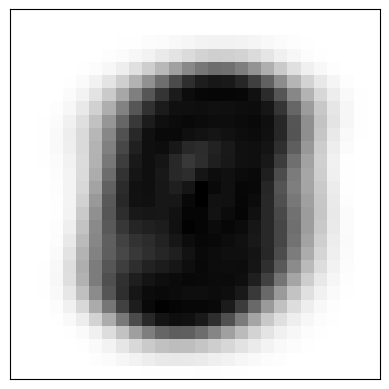

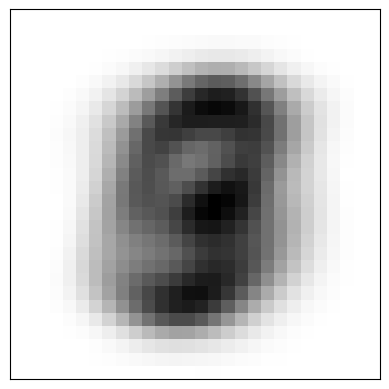

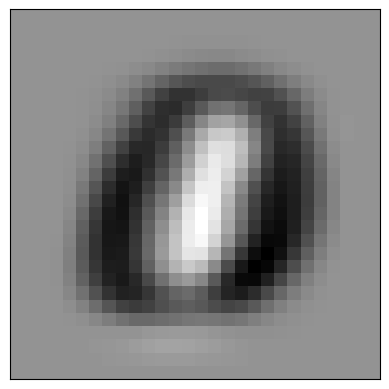

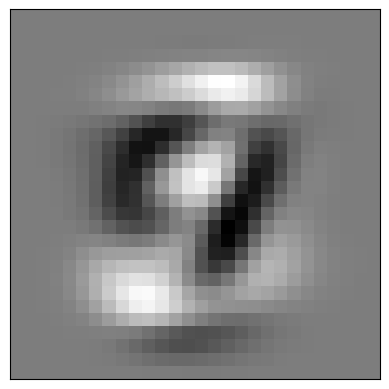

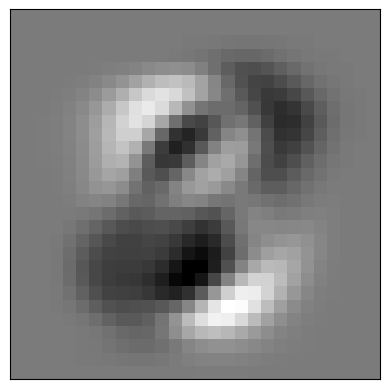

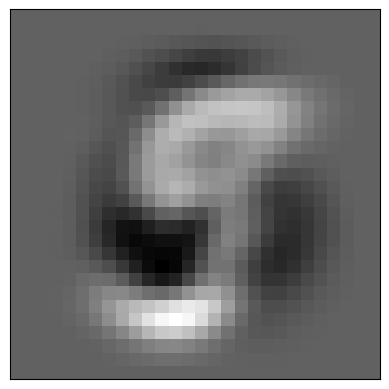

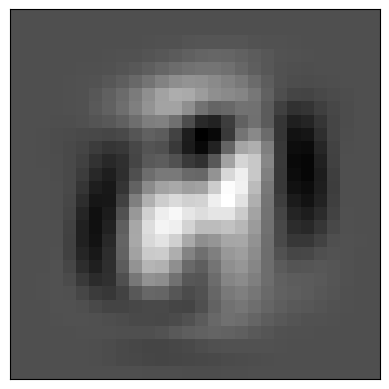

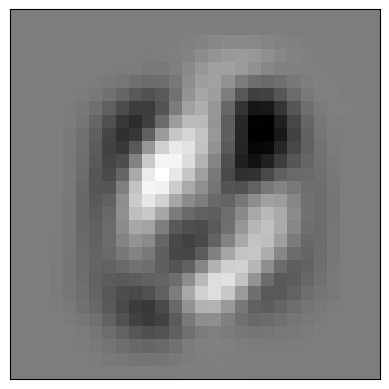

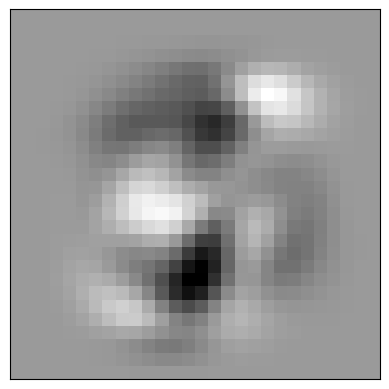

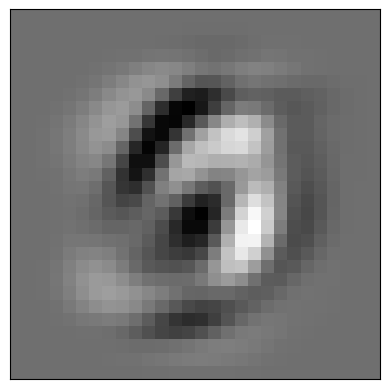

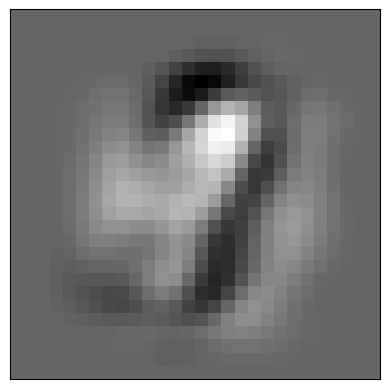

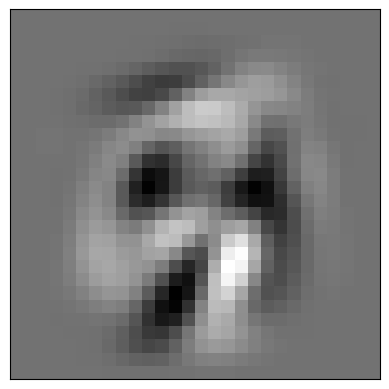

In [ ]:
#example with variance
plt.figure()
fig = plt.imshow(np.asarray(var_img).reshape(28,28),origin = 'upper')
fig.set_cmap('gray_r')
fig.axes.get_xaxis().set_visible(False)
fig.axes.get_yaxis().set_visible(False)
plt.show()
plt.close()

#do the same with the mean
plt.figure()
fig = plt.imshow(np.asarray(mean_img).reshape(28,28),origin = 'upper')
fig.set_cmap('gray_r')
fig.axes.get_xaxis().set_visible(False)
fig.axes.get_yaxis().set_visible(False)
plt.show()
plt.close()

#and the 10 eigenvectors
for i in range(10): #select the first 10 eigenvectors. complete the ...
  plt.figure()
  fig = plt.imshow(np.asarray(eigvec[:,i]).reshape(28,28),origin = 'upper')
  fig.set_cmap('gray_r')
  fig.axes.get_xaxis().set_visible(False)
  fig.axes.get_yaxis().set_visible(False)
  plt.show()
  plt.close()

## Plot the first 100 eigenvalues

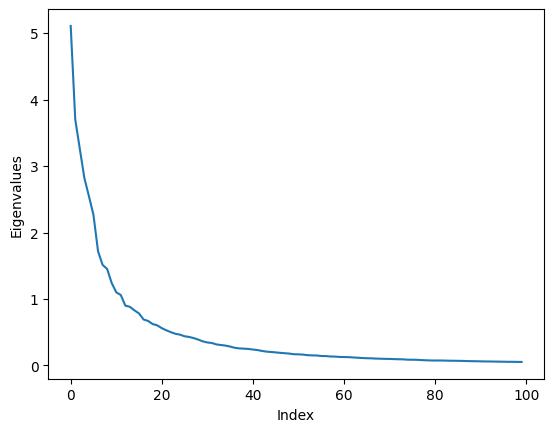

In [ ]:
#complete the ...
plt.figure()
fig = plt.plot(np.asarray(eigval[:100]))
plt.xlabel('Index')
plt.ylabel('Eigenvalues')
plt.show()
plt.close()

# Report

Answer the following questions.

1.   Why do we need to compute the covariance matrix in order to get the eigenvalues and eigenvectors?
2.   What do you think the eigenvector images capture? And the eigenvalues?
3.  Does the pixelwise mean and variance have any informative value about the dataset? In which other way can you compute the mean and variance of the dataset that would provide some characterization of the dataset?
4.   Conclude with some thoughts and things you learned from this homework.


**My Answers**

1. When we compute eigenvectors and eigenvalues, we must use the covariance matrix in order for the eigenvector images to clearly reveal the main patterns of the data. In other words, without the covariance matrix, they would simply be vectors pointing in random directions.Only by using the covariance matrix can we obtain eigenvectors and eigenvalues that reflect the true structure and patterns of the data, resulting in meaningful eigenvector images.

2. I think the eigevetor images show a main pattern about that data and the eigenvalue represents how important that pattern.

3. The pixelwise mean shows the average brightness at each specific pixel location across the dataset and the pixelwise variance measures how much the brightness at that location varies. These statistics reveal which regions are stable(low variance) or variable(high variance), providing useful information about overall structure and noise. I can also calculate the mean and variance for each image as a whole to describe its total brightness and contrast. Another approach is computing mean and variance within each class label which helps capture class-specific visual characteristics like the typical shape of the digit 1 in handwriting datasets.

4. Through this homework, I learned about the covariance matrix, the eigenvector and the eigenvalue from the linear algebra lecture, but at first i didn't cleary understand how they are related. While working on the report question, i had to study this connection myself. Finally, i get some knowledge how the eigenvectors of the covariance matrix represent the principal directions of data variation and how their corresponding eigenvalues indicate the amount of variance along those directions. This helped me understand why eigenvectors and eigenvalues are essential in methods like PCA for reducing dimensions and capturing the most important patterns in data. Overall, this homework strengthened both my theoretical understanding and my ability to learn independently when concepts are not immediately clear.

** I used GenAI to unnatural parts of my English.